In [1]:
import pandas as pd
import numpy as np
from scipy import signal
import matplotlib.pyplot as plt


# 1. 打开TXT文件
txt = "four_14_ssvep"
txt_file = f'../{txt}.txt'
num_channels = 8  # 假设有4个通道的EEG数据
num_components = 7
num_trials_train = 15

df = pd.read_csv(txt_file, sep='\t')
print("✓ TXT文件已加载")
print(f"  数据形状: {df.shape}")
print(f"\n前5行:\n{df.head()}")

✓ TXT文件已加载
  数据形状: (19731, 1)

前5行:
  [15176.154552] {'fn': 0, 'eeg': [6812383, -2544092, -2751266, -3273174, -1462422, -1970696, 1030739, -1345639]}
0  [15176.1584555] {'fn': 1, 'eeg': [6811627, -25...                                                             
1  [15176.162488] {'fn': 2, 'eeg': [6810938, -254...                                                             
2  [15176.1665126] {'fn': 3, 'eeg': [6811654, -25...                                                             
3  [15176.1704763] {'fn': 4, 'eeg': [6812108, -25...                                                             
4  [15176.1778278] {'fn': 5, 'eeg': [6811683, -25...                                                             


In [2]:
# 2. 读取N行第一列的数据，并提取字符串的第一个单位
N = df.shape[0]  # 修改为所需的行数
col_index = 0  # 第一列的索引
raw_data = df.iloc[0:N, col_index].values

In [3]:
index = []
timestamps = []
events = []
eeg = [[] for _ in range(num_channels)]  # 假设有8个通道的EEG数据
for i, item in enumerate(raw_data):
    index.append(i)
    if 'start' in str(item):
        events.append([i, 'start'])
    elif 'pause' in str(item):
        events.append([i, 'pause'])
    elif 'blink' in str(item):
        events.append([i, 'blink'])
    timestamp = item.split('[')[1].split(']')[0]
    print(f"提取的时间戳字符串: {timestamp}")
    eeg_datas = item.split('[')[2].split(']')[0]
    print(f"提取的EEG数据字符串: {eeg_datas}")
    eeg_data = [float(x) for x in eeg_datas.split(',')]
    print(f"提取的EEG数据列表: {eeg_data}")
    for i in range(num_channels):
        eeg[i].append(eeg_data[i])
    timestamps.append(timestamp)


提取的时间戳字符串: 15176.1584555
提取的EEG数据字符串: 6811627, -2544362, -2750908, -3273744, -1463372, -1971123, 1030235, -1346052
提取的EEG数据列表: [6811627.0, -2544362.0, -2750908.0, -3273744.0, -1463372.0, -1971123.0, 1030235.0, -1346052.0]
提取的时间戳字符串: 15176.162488
提取的EEG数据字符串: 6810938, -2543936, -2749947, -3275179, -1462775, -1970885, 1030712, -1346464
提取的EEG数据列表: [6810938.0, -2543936.0, -2749947.0, -3275179.0, -1462775.0, -1970885.0, 1030712.0, -1346464.0]
提取的时间戳字符串: 15176.1665126
提取的EEG数据字符串: 6811654, -2543706, -2749500, -3274889, -1462767, -1970307, 1031203, -1346247
提取的EEG数据列表: [6811654.0, -2543706.0, -2749500.0, -3274889.0, -1462767.0, -1970307.0, 1031203.0, -1346247.0]
提取的时间戳字符串: 15176.1704763
提取的EEG数据字符串: 6812108, -2544161, -2750442, -3273711, -1462875, -1971076, 1030521, -1346260
提取的EEG数据列表: [6812108.0, -2544161.0, -2750442.0, -3273711.0, -1462875.0, -1971076.0, 1030521.0, -1346260.0]
提取的时间戳字符串: 15176.1778278
提取的EEG数据字符串: 6811683, -2544978, -2751411, -3273778, -1463074, -1971526, 1029520, -134631

In [4]:
print(events)
trials = []
for i, event in enumerate(events):
    if event[1] == 'blink' and i+1 < len(events):
        trials.append([events[i][0], events[i+1][0]])
print(trials)
print(len(trials))
num_trials_train = len(trials) - 1 


[[4, 'pause'], [504, 'blink'], [1003, 'pause'], [1502, 'blink'], [2001, 'pause'], [2500, 'blink'], [2999, 'pause'], [3498, 'blink'], [3997, 'pause'], [4496, 'blink'], [4995, 'pause'], [5493, 'blink'], [5992, 'pause'], [6492, 'blink'], [6990, 'pause'], [7489, 'blink'], [7988, 'pause'], [8487, 'blink'], [8986, 'pause'], [9486, 'blink'], [9984, 'pause'], [10483, 'blink'], [10982, 'pause'], [11481, 'blink'], [11980, 'pause'], [12479, 'blink'], [12978, 'pause'], [13477, 'blink'], [13976, 'pause'], [14475, 'blink'], [14974, 'pause'], [15473, 'blink'], [15972, 'pause'], [16471, 'blink'], [16970, 'pause'], [17468, 'blink'], [17967, 'pause'], [18466, 'blink'], [18965, 'pause'], [19464, 'blink']]
[[504, 1003], [1502, 2001], [2500, 2999], [3498, 3997], [4496, 4995], [5493, 5992], [6492, 6990], [7489, 7988], [8487, 8986], [9486, 9984], [10483, 10982], [11481, 11980], [12479, 12978], [13477, 13976], [14475, 14974], [15473, 15972], [16471, 16970], [17468, 17967], [18466, 18965]]
19


[6816534.0, 6814998.0, 6815744.0, 6817319.0, 6817674.0, 6816368.0, 6815523.0, 6815828.0, 6816932.0, 6818293.0, 6816928.0, 6815098.0, 6815889.0, 6817461.0, 6818492.0, 6818114.0, 6816094.0, 6816276.0, 6817166.0, 6819140.0, 6817000.0, 6814938.0, 6815944.0, 6817429.0, 6817585.0, 6816053.0, 6814950.0, 6815564.0, 6816544.0, 6818551.0, 6817498.0, 6816287.0, 6816429.0, 6816998.0, 6819055.0, 6817412.0, 6815128.0, 6816549.0, 6817358.0, 6818614.0, 6818858.0, 6815086.0, 6814668.0, 6816568.0, 6818528.0, 6816935.0, 6816623.0, 6817792.0, 6817536.0, 6819508.0, 6817831.0, 6816268.0, 6817511.0, 6817688.0, 6819279.0, 6817805.0, 6815043.0, 6814374.0, 6816789.0, 6818477.0, 6818037.0, 6815980.0, 6816273.0, 6817980.0, 6819671.0, 6819779.0, 6817690.0, 6817414.0, 6817324.0, 6818734.0, 6817461.0, 6815138.0, 6815428.0, 6816994.0, 6817924.0, 6816830.0, 6815079.0, 6815572.0, 6817126.0, 6818214.0, 6816114.0, 6814848.0, 6817403.0, 6818626.0, 6817798.0, 6817351.0, 6816151.0, 6817272.0, 6818417.0, 6818779.0, 6817394.0

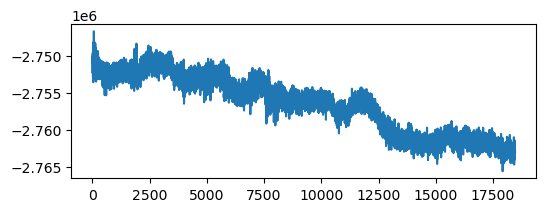

In [5]:
from scipy.signal import butter, filtfilt

fs = 250    # 采样率
low = 5     # 低频截止
high = 50    # 高频截止
order = 4

# 直接滤波，不写额外函数
b, a = butter(order, [low/(fs/2), high/(fs/2)], btype='band')

num_trials = len(trials)
eeg_seg = [[] for i in range(num_channels)]
for i in range(num_channels):
    eeg_seg[i] = eeg[i][trials[0][0]:trials[num_trials-1][1]]
    # eeg_seg[i] = eeg_seg[i] - np.mean(eeg_seg[i])
    # eeg_seg[i] = eeg_seg[i] / np.var(eeg_seg[i]) *  1000
    # eeg_seg[i] = filtfilt(b, a, eeg_seg[i])

print(eeg_seg[0])
print(len(eeg_seg[0]))
plt.figure(figsize=(6, 2))
plt.plot(eeg_seg[2])

In [6]:
eeg_trials = []
eeg_labels = []
min_timepoints = 1000
for trial_test in range(num_trials_train):
    for i in range(num_channels):
        blink_timepoints = trials[trial_test][1]-trials[trial_test][0]
        pause_timepoints = trials[trial_test+1][0]-trials[trial_test][1]
        min_timepoints_trail = min(blink_timepoints, pause_timepoints)
        min_timepoints = min(min_timepoints, min_timepoints_trail)


for trial_test in range(num_trials_train):
    eeg_test_blink = [[] for _ in range(num_channels)]
    eeg_test_pause = [[] for _ in range(num_channels)]
    for i in range(num_channels):
        eeg_test_blink[i] = eeg[i][trials[trial_test][0]: trials[trial_test][1]]
        eeg_test_blink[i] = filtfilt(b, a, eeg_test_blink[i])
        eeg_test_blink[i] = eeg_test_blink[i] - np.mean(eeg_test_blink[i])
        eeg_test_blink[i] = eeg_test_blink[i] / np.var(eeg_test_blink[i]) *  1000
        eeg_test_pause[i] = eeg[i][trials[trial_test][1]: trials[trial_test+1][0]]
        eeg_test_pause[i] = filtfilt(b, a, eeg_test_pause[i])
        eeg_test_pause[i] = eeg_test_pause[i] - np.mean(eeg_test_pause[i])
        eeg_test_pause[i] = eeg_test_pause[i] / np.var(eeg_test_pause[i]) *  1000
        eeg_test_blink[i] = eeg_test_blink[i][:min_timepoints]
        eeg_test_pause[i] = eeg_test_pause[i][:min_timepoints]
        
    eeg_trials.append([eeg_test_blink, eeg_test_pause])
    eeg_labels.append([0, 1])

np.save('eeg_trials.npy', eeg_trials)
np.save('eeg_labels.npy', eeg_labels)

from scipy.io import savemat
savemat(f'eeg_data_{txt}.mat', {
    'eeg': np.array(eeg_trials).transpose(1, 2, 3, 0),
})
print(np.array(eeg_trials).shape)

(18, 2, 8, 498)


In [7]:
from sklearn.decomposition import FastICA
S = np.array(eeg_seg).T
ica = FastICA(n_components=num_components)
D = ica.fit_transform(S)

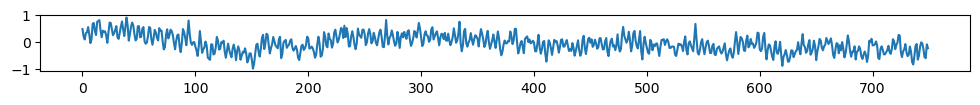

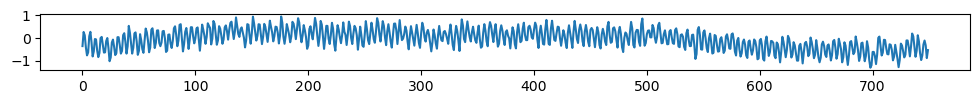

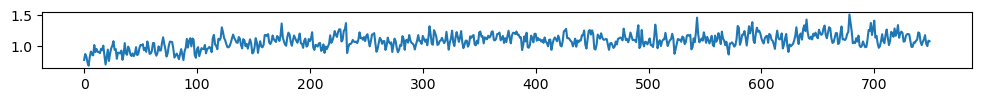

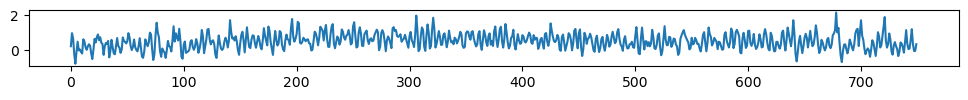

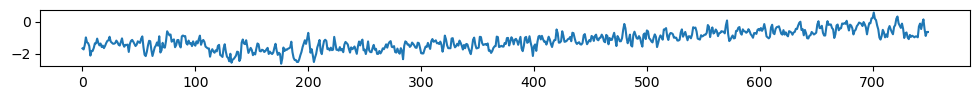

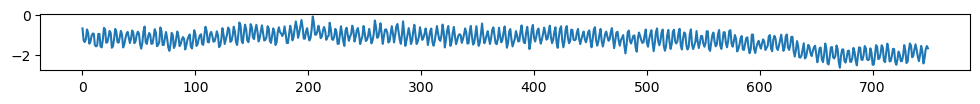

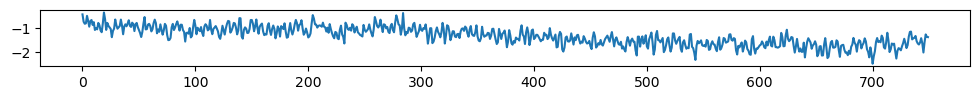

In [8]:
for i in range(num_components):
    plt.figure(figsize=(12, 6))
    plt.subplot(num_components, 1, i + 1)
    plt.plot(D[10000:10750, i])

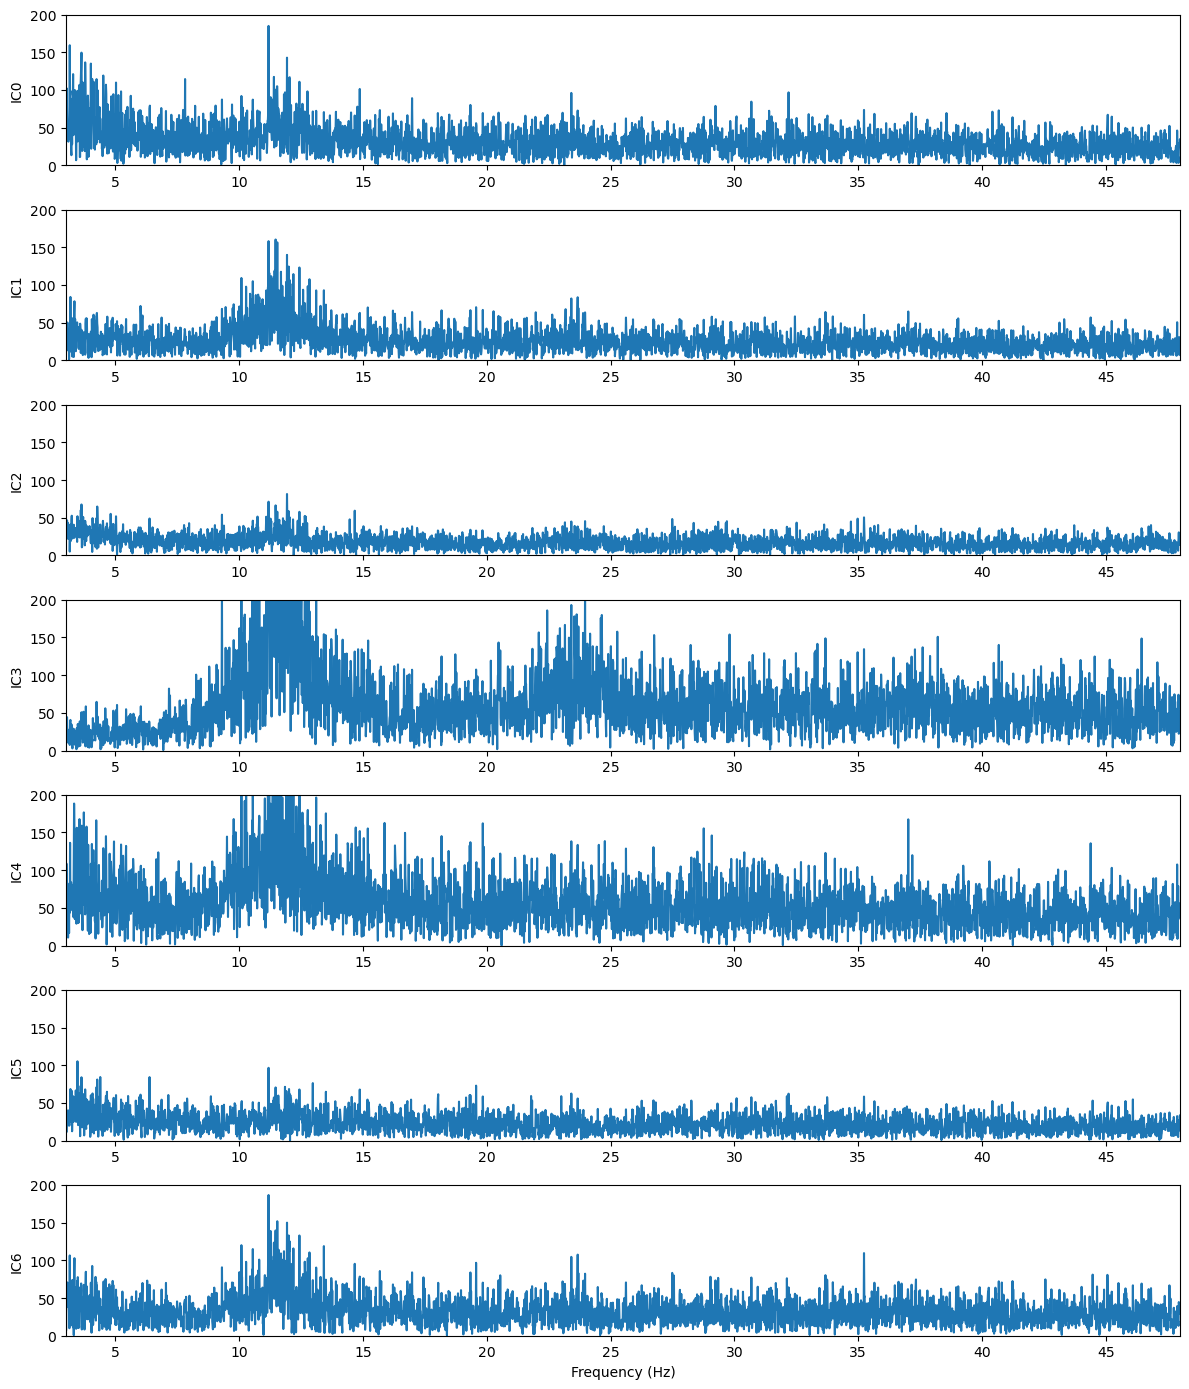

In [9]:
from scipy import signal

fs = 250  # 你的采样率，改成实际的

plt.figure(figsize=(12, 14))
for i in range(num_components):
    plt.subplot(num_components, 1, i + 1)
    x = D[:, i]
    
    freqs = np.fft.rfftfreq(len(x), 1/fs)
    spectrum = np.abs(np.fft.rfft(x))
    
    plt.plot(freqs, spectrum)
    plt.xlim(3, 48)  # EEG 只看 0-50 Hz
    plt.ylabel(f'IC{i}')
    plt.ylim(0, 200)
    
plt.xlabel('Frequency (Hz)')
plt.tight_layout()
plt.show()

In [10]:
print(len(eeg_trials))
print(len(eeg_trials[0]))
print(len(eeg_trials[0][0]))
print(len(eeg_trials[0][0][0]))


18
2
8
498


In [11]:
from sklearn.decomposition import FastICA
S = np.array(eeg_seg).T
ica = FastICA(n_components=num_components)
D = ica.fit_transform(S)

d:\software\IDEA\anaconda\Lib\site-packages\sklearn\decomposition\_fastica.py:128: ConvergenceWarning: FastICA did not converge. Consider increasing tolerance or the maximum number of iterations.
  warnings.warn(


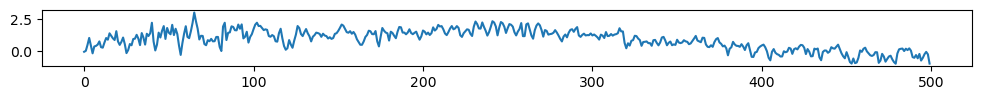

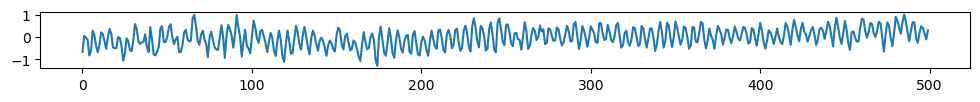

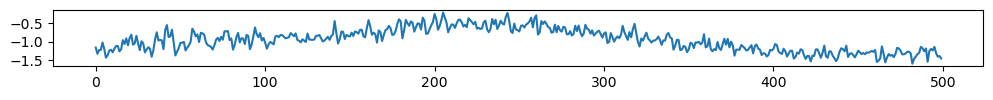

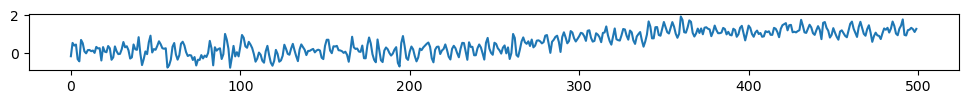

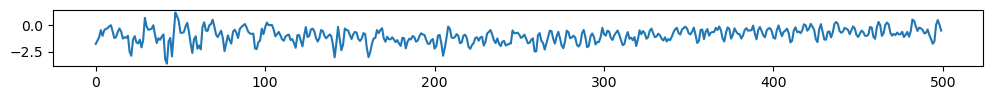

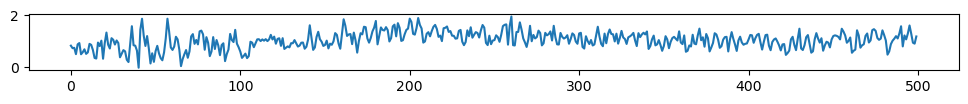

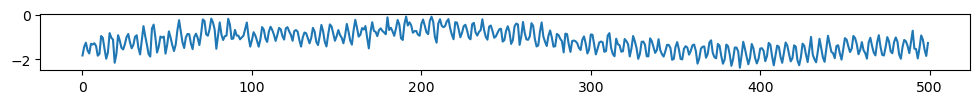

In [12]:
for i in range(num_components):
    plt.figure(figsize=(12, 6))
    plt.subplot(num_components, 1, i + 1)
    plt.plot(D[0:500, i])

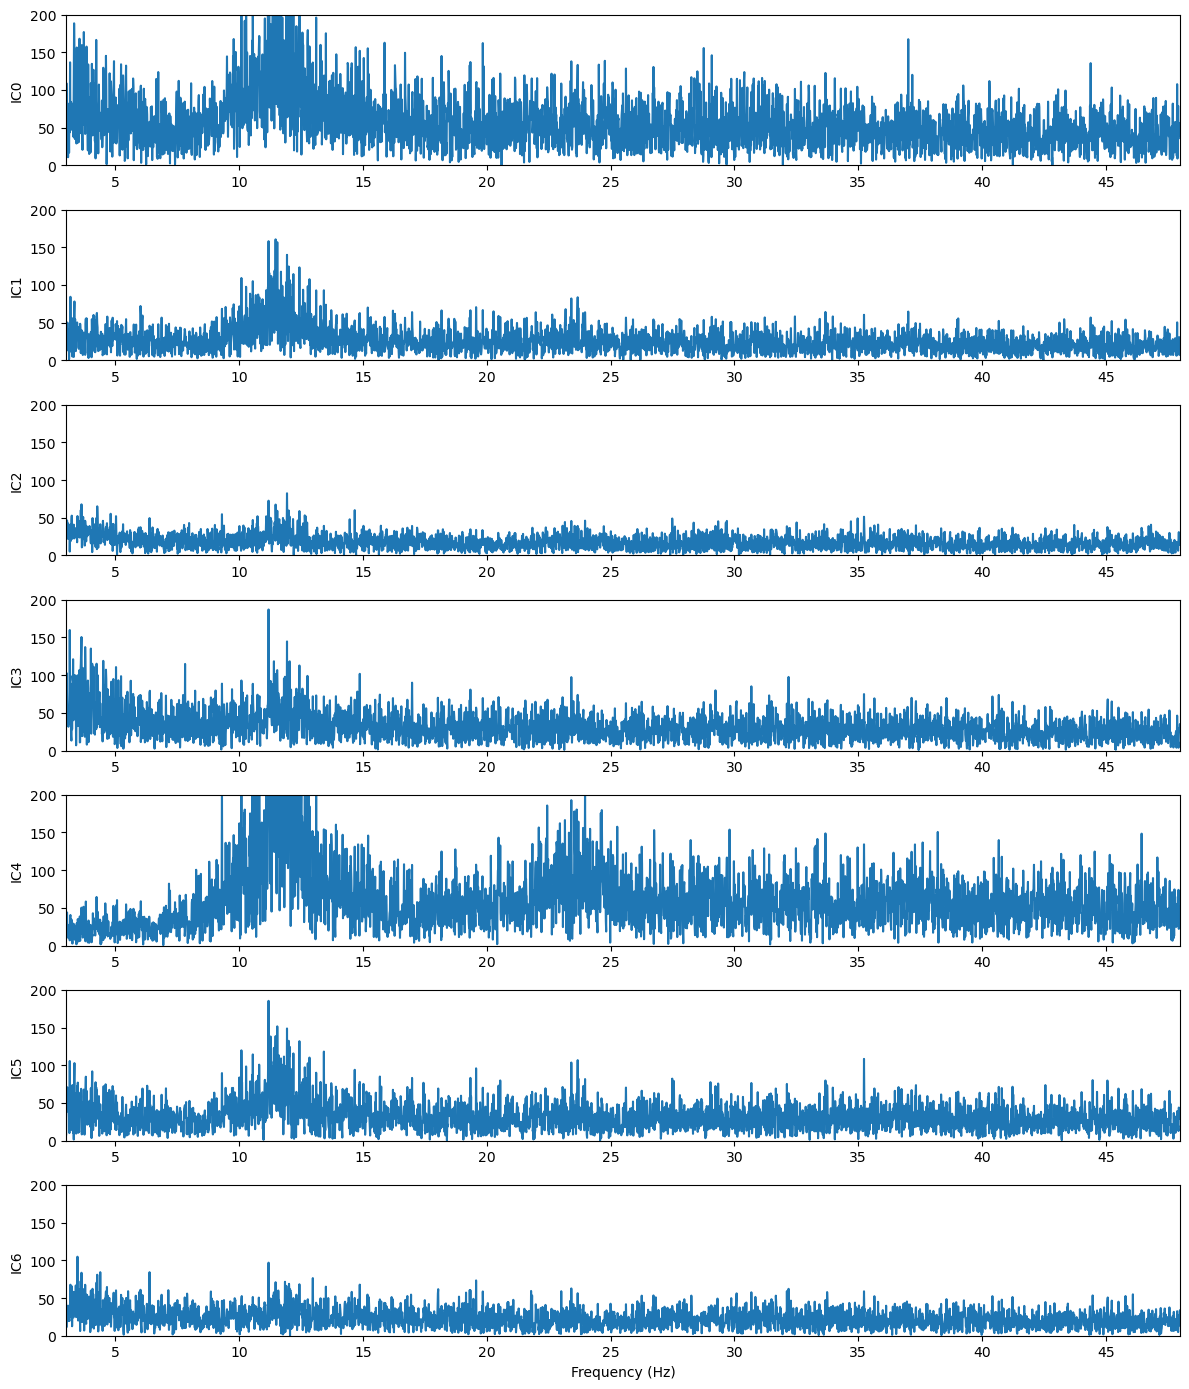

In [13]:
from scipy import signal

fs = 250  # 你的采样率，改成实际的

plt.figure(figsize=(12, 14))
for i in range(num_components):
    plt.subplot(num_components, 1, i + 1)
    x = D[:, i]
    
    freqs = np.fft.rfftfreq(len(x), 1/fs)
    spectrum = np.abs(np.fft.rfft(x))
    
    plt.plot(freqs, spectrum)
    plt.xlim(3, 48)  # EEG 只看 0-50 Hz
    plt.ylabel(f'IC{i}')
    plt.ylim(0, 200)
    
plt.xlabel('Frequency (Hz)')
plt.tight_layout()
plt.show()

In [14]:
# 

####           test

In [15]:
# print(trials)
# print(len(trials))

In [16]:
# trial_test = 14
# eeg_test_blink = [[] for _ in range(7)]
# eeg_test_pause = [[] for _ in range(7)]

# for i in range(7):
#     eeg_test_blink[i] = eeg[i][trials[trial_test][0]: trials[trial_test][1]]
#     eeg_test_blink[i] = eeg_test_blink[i] - np.mean(eeg_test_blink[i])
#     eeg_test_blink[i] = eeg_test_blink[i] / np.var(eeg_test_blink[i]) *  1000
#     eeg_test_pause[i] = eeg[i][trials[trial_test][1]: trials[trial_test+1][0]]
#     eeg_test_pause[i] = eeg_test_pause[i] - np.mean(eeg_test_pause[i])
#     eeg_test_pause[i] = eeg_test_pause[i] / np.var(eeg_test_pause[i]) *  1000


In [17]:
# print(eeg_test_blink[0])
# print(len(eeg_test_blink[0]))
# plt.figure(figsize=(6, 2))
# plt.plot(eeg_test_blink[0])

In [18]:
# ## blink
# num_components = 5
# S_test = np.array(eeg_test_blink).T
# D_test = ica.fit_transform(S_test)
# for i in range(num_components):
#     plt.figure(figsize=(12, 6))
#     plt.subplot(num_components, 1, i + 1)
#     plt.plot(D_test[:, i])
    
# fs = 250  # 你的采样率，改成实际的
# plt.figure(figsize=(12, 6))
# for i in range(num_components):
#     plt.subplot(num_components, 1, i + 1)
#     x = D_test[:, i]
#     freqs = np.fft.rfftfreq(len(x), 1/fs)
#     spectrum = np.abs(np.fft.rfft(x))
#     plt.plot(freqs, spectrum)
#     plt.xlim(3, 48)  # EEG 只看 0-50 Hz
#     plt.ylabel(f'IC{i}')
#     plt.ylim(0, 200)
# plt.xlabel('Frequency (Hz)')
# plt.tight_layout()
# plt.show()

In [19]:
# ## pause
# num_components = 5
# S_test = np.array(eeg_test_pause).T
# D_test = ica.fit_transform(S_test)
# for i in range(num_components):
#     plt.figure(figsize=(12, 6))
#     plt.subplot(num_components, 1, i + 1)
#     plt.plot(D_test[:, i])
    
# fs = 250  # 你的采样率，改成实际的
# plt.figure(figsize=(12, 6))
# for i in range(num_components):
#     plt.subplot(num_components, 1, i + 1)
#     x = D_test[:, i]
#     freqs = np.fft.rfftfreq(len(x), 1/fs)
#     spectrum = np.abs(np.fft.rfft(x))
#     plt.plot(freqs, spectrum)
#     plt.xlim(3, 48)  # EEG 只看 0-50 Hz
#     plt.ylabel(f'IC{i}')
#     plt.ylim(0, 200)
# plt.xlabel('Frequency (Hz)')
# plt.tight_layout()
# plt.show()

In [20]:
# 

In [21]:
# 

In [22]:
# 

### recon

In [23]:
# D_recon = np.zeros_like(D)  # 形状: (23190, 7)
# D_recon[:, 1] = D[:, 1]  # 只保留第2个独立成分
# D_reconstructed = ica.inverse_transform(D_recon)  # 形状: (23190, 1)


In [24]:
# fs = 250  # 你的采样率，改成实际的

# plt.figure(figsize=(12, 7))
# for i in range(num_components):
#     plt.subplot(num_components, 1, i + 1)
#     x = D_reconstructed[:, i]
    
#     freqs = np.fft.rfftfreq(len(x), 1/fs)
#     spectrum = np.abs(np.fft.rfft(x))
    
#     plt.plot(freqs, spectrum)
#     plt.xlim(3, 48)  # EEG 只看 0-50 Hz
#     plt.ylabel(f'IC{i}')
#     plt.ylim(0, 10)
    
# plt.xlabel('Frequency (Hz)')
# plt.tight_layout()
# plt.show()

In [25]:
# for i in range(len(num_trials)):
#     eeg_trial = eeg_seg[0][trials[i][0]:trials[i][1]]

In [26]:
# 